# ITRI625 Project – Deep Learning Intrusion Detection

**Dataset:** [Cybersecurity Intrusion Detection Dataset](https://www.kaggle.com/datasets/dnkumars/cybersecurity-intrusion-detection-dataset) (Kaggle)

**Task:** Binary classification – predict whether a network/login session
(`attack_detected`) is a normal session (0) or an intrusion / attack (1),
using an MLP (Multi-Layer Perceptron) deep learning model built with
TensorFlow/Keras.

**Rubric coverage in this notebook:**
| Rubric item | Section below |
|---|---|
| 2.1 Model development | Sections 4-5 |
| 2.2 Train/val/test split | Section 3 |
| 2.3 Evaluation metric logging | Sections 5-6 |
| 2.4 Metric graphs | Section 7 |
| 2.6 Patience / early stopping | Section 5 |
| 2.7 Additional features (XAI bonus) | Section 8 |

The desktop application (2.5) and its API are in `../api/api.py` and
`../desktop_app/desktop_app.py` — see the project `README.md`.

---
**Before running:** download `cybersecurity_intrusion_data.csv` from the
Kaggle link above and place it in the `../data/` folder next to this
notebook (see `../data/README.md` for exact instructions).


## 0. Imports and reproducibility setup

In [3]:
import os
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, precision_recall_curve, confusion_matrix,
    ConfusionMatrixDisplay, classification_report
)

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
tf.random.set_seed(RANDOM_STATE)

sns.set_theme(style="whitegrid")

DATA_PATH = "C:/Users/S_CSIS-PostGrad/Desktop/itri625_ML/cybersecurity_intrusion_data.csv"
MODEL_DIR = "../models"
os.makedirs(MODEL_DIR, exist_ok=True)

print("TensorFlow version:", tf.__version__)


TensorFlow version: 2.21.0


## 1. Load the dataset

The raw dataset contains the following columns:

| Column | Type | Description |
|---|---|---|
| `session_id` | id | Unique session identifier (dropped before modelling) |
| `network_packet_size` | numeric | Size of network packets in the session |
| `protocol_type` | categorical | TCP / UDP / ICMP |
| `login_attempts` | numeric | Number of login attempts in the session |
| `session_duration` | numeric | Session length in seconds |
| `encryption_used` | categorical | AES / DES / missing (no encryption) |
| `ip_reputation_score` | numeric | 0-1 reputation score of the source IP |
| `failed_logins` | numeric | Number of failed login attempts |
| `browser_type` | categorical | Browser used for the session |
| `unusual_time_access` | binary | 1 if access occurred at an unusual time |
| `attack_detected` | **target** | 0 = normal session, 1 = attack |


In [4]:
df = pd.read_csv(DATA_PATH)
df.columns = [c.strip() for c in df.columns]

print("Shape:", df.shape)
df.head()


Shape: (9537, 11)


,session_id,network_packet_size,protocol_type,login_attempts,session_duration,encryption_used,ip_reputation_score,failed_logins,browser_type,unusual_time_access,attack_detected
0,SID_00001,599,TCP,4,492.983263,DES,0.606818,1,Edge,0,1
1,SID_00002,472,TCP,3,1557.996461,DES,0.301569,0,Firefox,0,0
2,SID_00003,629,TCP,3,75.044262,DES,0.739164,2,Chrome,0,1
3,SID_00004,804,UDP,4,601.248835,DES,0.123267,0,Unknown,0,1
4,SID_00005,453,TCP,5,532.540888,AES,0.054874,1,Firefox,0,0


In [5]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 9537 entries, 0 to 9536
Data columns (total 11 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   session_id           9537 non-null   str    
 1   network_packet_size  9537 non-null   int64  
 2   protocol_type        9537 non-null   str    
 3   login_attempts       9537 non-null   int64  
 4   session_duration     9537 non-null   float64
 5   encryption_used      7571 non-null   str    
 6   ip_reputation_score  9537 non-null   float64
 7   failed_logins        9537 non-null   int64  
 8   browser_type         9537 non-null   str    
 9   unusual_time_access  9537 non-null   int64  
 10  attack_detected      9537 non-null   int64  
dtypes: float64(2), int64(5), str(4)
memory usage: 819.7 KB


In [6]:
df.describe(include="all").T


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
session_id,9537,9537,SID_00001,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
network_packet_size,9537.0,NaN,NaN,NaN,500.430639,198.379364,64.0,365.0,499.0,635.0,1285.0
protocol_type,9537,3,TCP,6624,NaN,NaN,NaN,NaN,NaN,NaN,NaN
login_attempts,9537.0,NaN,NaN,NaN,4.032086,1.963012,1.0,3.0,4.0,5.0,13.0
session_duration,9537.0,NaN,NaN,NaN,792.745312,786.560144,0.5,231.953006,556.277457,1105.380602,7190.392213
encryption_used,7571,2,AES,4706,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ip_reputation_score,9537.0,NaN,NaN,NaN,0.331338,0.177175,0.002497,0.191946,0.314778,0.453388,0.924299
failed_logins,9537.0,NaN,NaN,NaN,1.517773,1.033988,0.0,1.0,1.0,2.0,5.0
browser_type,9537,5,Chrome,5137,NaN,NaN,NaN,NaN,NaN,NaN,NaN
unusual_time_access,9537.0,NaN,NaN,NaN,0.149942,0.357034,0.0,0.0,0.0,0.0,1.0


## 2. Exploratory data analysis (EDA)

In [7]:
print("Missing values per column:")
print(df.isna().sum())


Missing values per column:
session_id                0
network_packet_size       0
protocol_type             0
login_attempts            0
session_duration          0
encryption_used        1966
ip_reputation_score       0
failed_logins             0
browser_type              0
unusual_time_access       0
attack_detected           0
dtype: int64


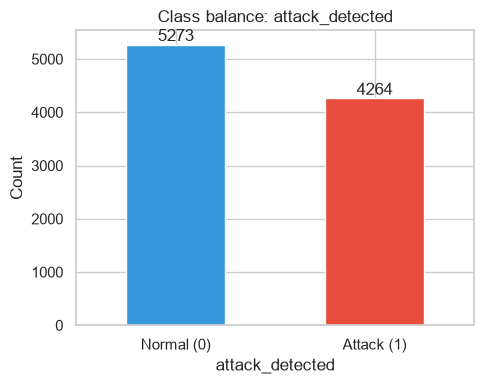

attack_detected
0    0.552899
1    0.447101
Name: proportion, dtype: float64


In [8]:
plt.figure(figsize=(5, 4))
ax = df["attack_detected"].value_counts().sort_index().plot(kind="bar", color=["#3498db", "#e74c3c"])
ax.set_xticklabels(["Normal (0)", "Attack (1)"], rotation=0)
ax.set_title("Class balance: attack_detected")
ax.set_ylabel("Count")
for p in ax.patches:
    ax.annotate(str(int(p.get_height())), (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom")
plt.tight_layout()
plt.show()

print(df["attack_detected"].value_counts(normalize=True).rename("proportion"))


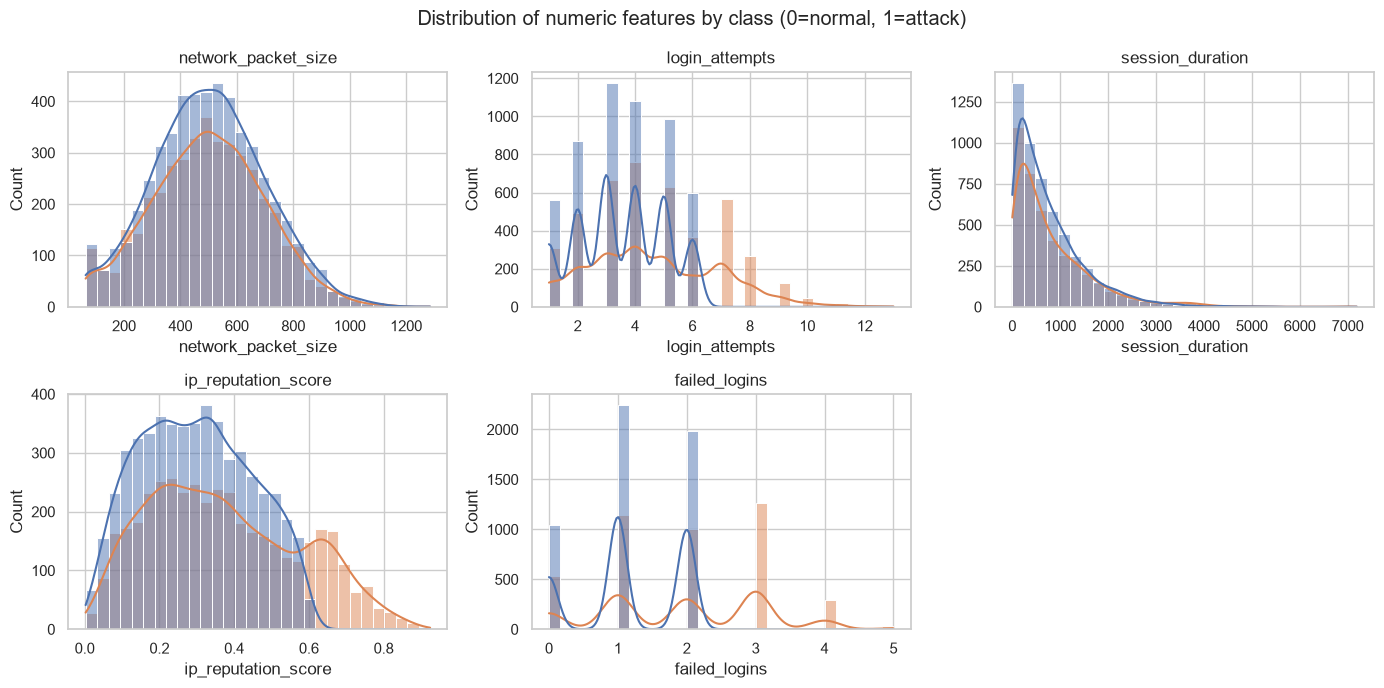

In [9]:
numeric_preview = ["network_packet_size", "login_attempts", "session_duration",
                    "ip_reputation_score", "failed_logins"]
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, col in zip(axes.ravel(), numeric_preview):
    sns.histplot(data=df, x=col, hue="attack_detected", bins=30, kde=True, ax=ax, legend=False)
    ax.set_title(col)
axes.ravel()[-1].axis("off")
fig.suptitle("Distribution of numeric features by class (0=normal, 1=attack)")
plt.tight_layout()
plt.show()


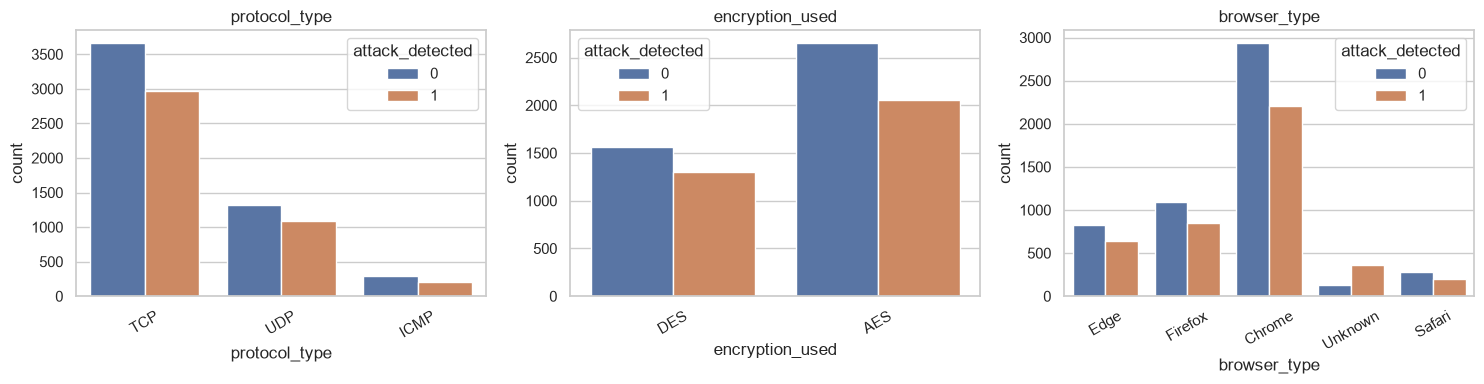

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["protocol_type", "encryption_used", "browser_type"]):
    sns.countplot(data=df, x=col, hue="attack_detected", ax=ax)
    ax.set_title(col)
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()


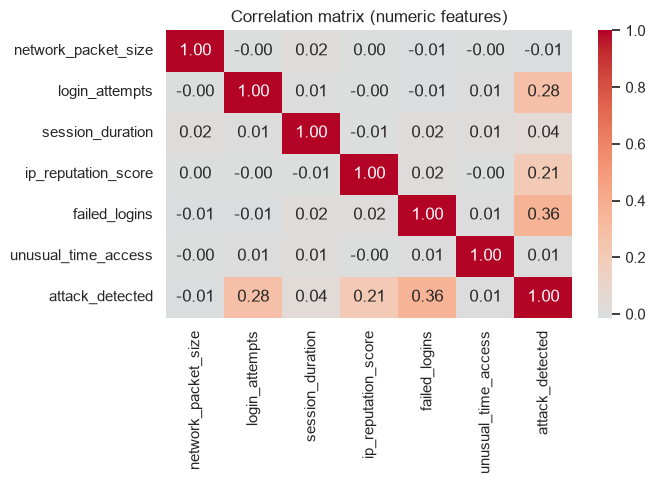

In [11]:
plt.figure(figsize=(7, 5))
corr = df.select_dtypes(include=[np.number]).corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation matrix (numeric features)")
plt.tight_layout()
plt.show()


## 3. Preprocessing and train / validation / test split (rubric 2.2)

Steps:
1. Drop `session_id` (identifier, not predictive).
2. Treat missing `encryption_used` as its own category (`"None"`) —
   a session that used no encryption is meaningful, not a data-quality gap.
3. Split into **60% train / 20% validation / 20% test**, stratified on the
   target so the class balance is preserved in every split.
4. Fit a `ColumnTransformer` (StandardScaler for numeric columns,
   OneHotEncoder for categorical columns) **on the training set only**,
   then apply it to validation/test to avoid data leakage.


In [12]:
TARGET = "attack_detected"
ID_COL = "session_id"

df = df.drop_duplicates()
if ID_COL in df.columns:
    df = df.drop(columns=[ID_COL])

if "encryption_used" in df.columns:
    df["encryption_used"] = df["encryption_used"].fillna("None")

CATEGORICAL_COLS = [c for c in ["protocol_type", "encryption_used", "browser_type"] if c in df.columns]
NUMERIC_COLS = [c for c in df.columns if c not in CATEGORICAL_COLS + [TARGET]]

print("Categorical columns:", CATEGORICAL_COLS)
print("Numeric columns:", NUMERIC_COLS)

X = df.drop(columns=[TARGET])
y = df[TARGET].astype(int)


Categorical columns: ['protocol_type', 'encryption_used', 'browser_type']
Numeric columns: ['network_packet_size', 'login_attempts', 'session_duration', 'ip_reputation_score', 'failed_logins', 'unusual_time_access']


In [13]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.4, stratify=y, random_state=RANDOM_STATE
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, stratify=y_temp, random_state=RANDOM_STATE
)

print("Train:", X_train.shape, " Val:", X_val.shape, " Test:", X_test.shape)
print("Train class balance:\n", y_train.value_counts(normalize=True))


Train: (5722, 9)  Val: (1907, 9)  Test: (1908, 9)
Train class balance:
 attack_detected
0    0.552954
1    0.447046
Name: proportion, dtype: float64


In [14]:
preprocessor = ColumnTransformer(transformers=[
    ("num", StandardScaler(), NUMERIC_COLS),
    ("cat", OneHotEncoder(handle_unknown="ignore"), CATEGORICAL_COLS),
])

X_train_proc = preprocessor.fit_transform(X_train)
X_val_proc = preprocessor.transform(X_val)
X_test_proc = preprocessor.transform(X_test)

if hasattr(X_train_proc, "toarray"):
    X_train_proc = X_train_proc.toarray()
    X_val_proc = X_val_proc.toarray()
    X_test_proc = X_test_proc.toarray()

n_features = X_train_proc.shape[1]
feature_names = preprocessor.get_feature_names_out()
print("Number of features after preprocessing:", n_features)
print(feature_names)

# Persist the fitted preprocessor so the API (api/api.py) can reuse it
# on new, raw input at inference time.
joblib.dump(preprocessor, os.path.join(MODEL_DIR, "preprocessor.joblib"))
joblib.dump(
    {"numeric_cols": NUMERIC_COLS, "categorical_cols": CATEGORICAL_COLS, "target": TARGET},
    os.path.join(MODEL_DIR, "feature_schema.joblib"),
)


Number of features after preprocessing: 17
['num__network_packet_size' 'num__login_attempts' 'num__session_duration'
 'num__ip_reputation_score' 'num__failed_logins'
 'num__unusual_time_access' 'cat__protocol_type_ICMP'
 'cat__protocol_type_TCP' 'cat__protocol_type_UDP'
 'cat__encryption_used_AES' 'cat__encryption_used_DES'
 'cat__encryption_used_None' 'cat__browser_type_Chrome'
 'cat__browser_type_Edge' 'cat__browser_type_Firefox'
 'cat__browser_type_Safari' 'cat__browser_type_Unknown']


['../models\\feature_schema.joblib']

## 4. Model development (rubric 2.1)

A feed-forward MLP (deep learning classifier) is used:

`Input -> Dense(64, relu) -> BatchNorm -> Dropout(0.3) -> Dense(32, relu)
-> BatchNorm -> Dropout(0.2) -> Dense(16, relu) -> Dense(1, sigmoid)`

- **Dropout + BatchNormalization** reduce overfitting and stabilise training.
- **Sigmoid output** gives a probability of `attack_detected = 1`.
- **Class weights** compensate for the class imbalance (attacks are the
  minority class) instead of naively optimising raw accuracy.


In [15]:
n_pos = y_train.sum()
n_neg = len(y_train) - n_pos
class_weight = {0: len(y_train) / (2 * n_neg), 1: len(y_train) / (2 * n_pos)}
print("Class weights:", class_weight)

def build_model(input_dim):
    model = keras.Sequential([
        layers.Input(shape=(input_dim,)),
        layers.Dense(64, activation="relu"),
        layers.BatchNormalization(),
        layers.Dropout(0.3),
        layers.Dense(32, activation="relu"),
        layers.BatchNormalization(),
        layers.Dropout(0.2),
        layers.Dense(16, activation="relu"),
        layers.Dense(1, activation="sigmoid"),
    ])
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1e-3),
        loss="binary_crossentropy",
        metrics=[
            keras.metrics.BinaryAccuracy(name="accuracy"),
            keras.metrics.Precision(name="precision"),
            keras.metrics.Recall(name="recall"),
            keras.metrics.AUC(name="auc"),
        ],
    )
    return model

model = build_model(n_features)
model.summary()


Class weights: {0: np.float64(0.9042351453855879), 1: np.float64(1.1184519155590305)}


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         1,152 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,161 (16.25 KB)

 Trainable params: 3,969 (15.50 KB)

 Non-trainable params: 192 (768.00 B)

## 5. Training with evaluation-metric logging and early stopping (rubric 2.3 & 2.6)

- Keras logs **accuracy, precision, recall, AUC-ROC and loss** after every
  epoch automatically (passed in `metrics=[...]` above).
- **F1-score** is not a built-in Keras metric, so a small custom
  `Callback` computes it on the validation set at the end of every epoch
  and appends it to the training history.
- `EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True)`
  implements the required **patience-based early stopping** (rubric 2.6):
  training stops once validation loss stops improving for 8 consecutive
  epochs, and the best weights are restored — this directly prevents
  overfitting/overtraining.


In [16]:
class F1History(keras.callbacks.Callback):
    """Logs F1-score on the validation set at the end of every epoch."""
    def __init__(self, X_val, y_val):
        super().__init__()
        self.X_val = X_val
        self.y_val = y_val
        self.f1_scores = []

    def on_epoch_end(self, epoch, logs=None):
        preds = (self.model.predict(self.X_val, verbose=0) > 0.5).astype(int).ravel()
        f1 = f1_score(self.y_val, preds, zero_division=0)
        self.f1_scores.append(f1)
        logs = logs or {}
        logs["val_f1"] = f1

f1_callback = F1History(X_val_proc, y_val.values)

early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=8,
    restore_best_weights=True,
    verbose=1,
)

history = model.fit(
    X_train_proc, y_train.values,
    validation_data=(X_val_proc, y_val.values),
    epochs=100,
    batch_size=64,
    class_weight=class_weight,
    callbacks=[early_stopping, f1_callback],
    verbose=2,
)


Epoch 1/100
90/90 - 2s - 21ms/step - accuracy: 0.6727 - auc: 0.7172 - loss: 0.6292 - precision: 0.6362 - recall: 0.6255 - val_accuracy: 0.7436 - val_auc: 0.8321 - val_loss: 0.5838 - val_precision: 0.6944 - val_recall: 0.7620 - val_f1: 0.7267
Epoch 2/100
90/90 - 0s - 3ms/step - accuracy: 0.7604 - auc: 0.8214 - loss: 0.5064 - precision: 0.7392 - recall: 0.7170 - val_accuracy: 0.8207 - val_auc: 0.8593 - val_loss: 0.4871 - val_precision: 0.8763 - val_recall: 0.6975 - val_f1: 0.7768
Epoch 3/100
90/90 - 0s - 3ms/step - accuracy: 0.7760 - auc: 0.8356 - loss: 0.4808 - precision: 0.7720 - recall: 0.7080 - val_accuracy: 0.8385 - val_auc: 0.8711 - val_loss: 0.4279 - val_precision: 0.9123 - val_recall: 0.7069 - val_f1: 0.7966
Epoch 4/100
90/90 - 0s - 3ms/step - accuracy: 0.7952 - auc: 0.8511 - loss: 0.4523 - precision: 0.8047 - recall: 0.7154 - val_accuracy: 0.8495 - val_auc: 0.8750 - val_loss: 0.3970 - val_precision: 0.9314 - val_recall: 0.7163 - val_f1: 0.8098
Epoch 5/100
90/90 - 0s - 3ms/step -

In [17]:
history_df = pd.DataFrame(history.history)
history_df["val_f1"] = f1_callback.f1_scores
history_df.index.name = "epoch"
history_df.to_csv(os.path.join(MODEL_DIR, "training_history.csv"))
history_df.tail(10)


,accuracy,auc,loss,precision,recall,val_accuracy,val_auc,val_loss,val_precision,val_recall,val_f1
epoch,,,,,,,,,,,
22,0.880112,0.898247,0.323762,0.968000,0.756841,0.886209,0.874117,0.312721,0.996875,0.747948,0.854655
23,0.879063,0.897923,0.324641,0.962339,0.759187,0.888306,0.876044,0.309925,0.993827,0.754982,0.858095
24,0.879413,0.895761,0.323341,0.964215,0.758405,0.884636,0.871060,0.315198,0.995305,0.745604,0.852547
25,0.879413,0.899106,0.321264,0.964215,0.758405,0.886209,0.871069,0.313188,0.996875,0.747948,0.854655
26,0.881160,0.899861,0.318316,0.969970,0.757623,0.885684,0.873929,0.311956,0.992248,0.750293,0.854473
27,0.877141,0.897819,0.324212,0.964447,0.752932,0.886209,0.873397,0.311637,0.995327,0.749121,0.854849
28,0.884306,0.898222,0.317626,0.972112,0.763096,0.887257,0.874680,0.310285,0.990769,0.754982,0.856953
29,0.885704,0.900478,0.314398,0.976000,0.763096,0.885160,0.875277,0.310505,0.995313,0.746776,0.853315
30,0.880986,0.899561,0.318668,0.963457,0.762705,0.883587,0.875281,0.312093,0.989147,0.747948,0.851802


## 6. Evaluation on the held-out test set

In [18]:
test_probs = model.predict(X_test_proc, verbose=0).ravel()
test_preds = (test_probs > 0.5).astype(int)

test_metrics = {
    "accuracy": accuracy_score(y_test, test_preds),
    "precision": precision_score(y_test, test_preds, zero_division=0),
    "recall": recall_score(y_test, test_preds, zero_division=0),
    "f1_score": f1_score(y_test, test_preds, zero_division=0),
    "auc_roc": roc_auc_score(y_test, test_probs),
}

print("Test-set metrics:")
for k, v in test_metrics.items():
    print(f"  {k:10s}: {v:.4f}")

print("\nFull classification report:")
print(classification_report(y_test, test_preds, target_names=["Normal", "Attack"]))

with open(os.path.join(MODEL_DIR, "test_metrics.json"), "w") as f:
    json.dump(test_metrics, f, indent=2)


Test-set metrics:
  accuracy  : 0.8941
  precision : 0.9837
  recall    : 0.7761
  f1_score  : 0.8676
  auc_roc   : 0.8882

Full classification report:
              precision    recall  f1-score   support

      Normal       0.85      0.99      0.91      1055
      Attack       0.98      0.78      0.87       853

    accuracy                           0.89      1908
   macro avg       0.91      0.88      0.89      1908
weighted avg       0.91      0.89      0.89      1908



## 7. Metric graphs (rubric 2.4)

Loss curve, accuracy curve, ROC curve, Precision-Recall curve and
confusion matrix — all plotted with Matplotlib and visible directly in
this notebook.


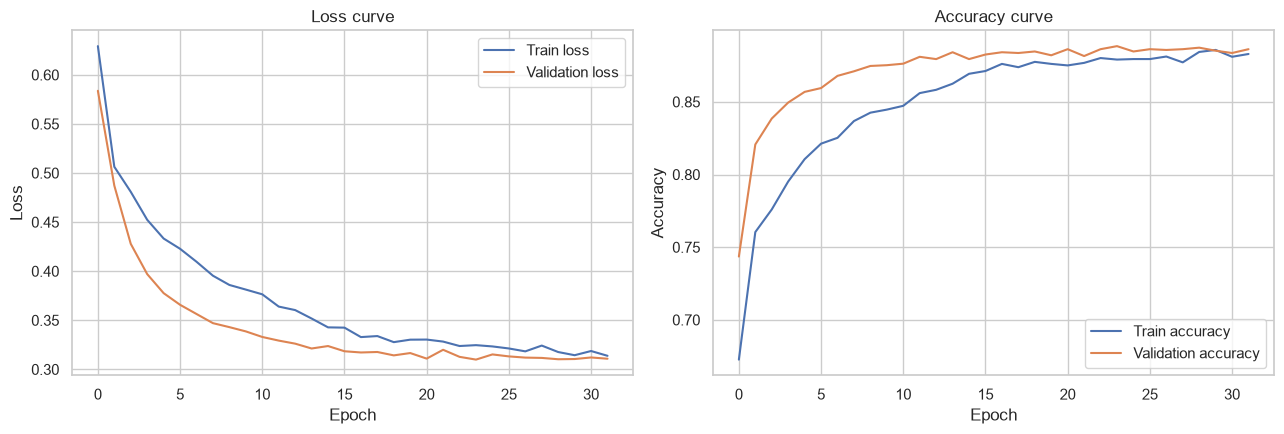

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].plot(history_df["loss"], label="Train loss")
axes[0].plot(history_df["val_loss"], label="Validation loss")
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Loss")
axes[0].set_title("Loss curve"); axes[0].legend()

axes[1].plot(history_df["accuracy"], label="Train accuracy")
axes[1].plot(history_df["val_accuracy"], label="Validation accuracy")
axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Accuracy")
axes[1].set_title("Accuracy curve"); axes[1].legend()

plt.tight_layout()
plt.savefig(os.path.join(MODEL_DIR, "loss_accuracy_curves.png"), dpi=120)
plt.show()


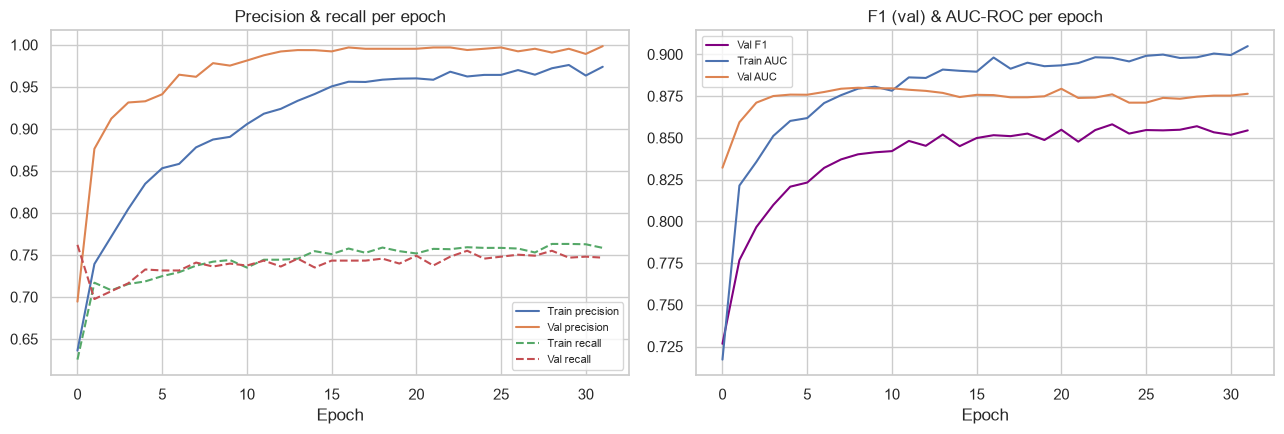

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].plot(history_df["precision"], label="Train precision")
axes[0].plot(history_df["val_precision"], label="Val precision")
axes[0].plot(history_df["recall"], label="Train recall", linestyle="--")
axes[0].plot(history_df["val_recall"], label="Val recall", linestyle="--")
axes[0].set_xlabel("Epoch"); axes[0].set_title("Precision & recall per epoch")
axes[0].legend(fontsize=8)

axes[1].plot(history_df["val_f1"], label="Val F1", color="purple")
axes[1].plot(history_df["auc"], label="Train AUC")
axes[1].plot(history_df["val_auc"], label="Val AUC")
axes[1].set_xlabel("Epoch"); axes[1].set_title("F1 (val) & AUC-ROC per epoch")
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.savefig(os.path.join(MODEL_DIR, "f1_auc_curves.png"), dpi=120)
plt.show()


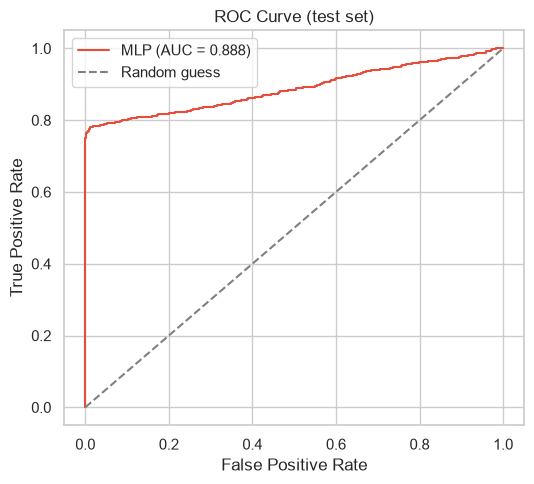

In [21]:
fpr, tpr, _ = roc_curve(y_test, test_probs)
plt.figure(figsize=(5.5, 5))
plt.plot(fpr, tpr, label=f"MLP (AUC = {test_metrics['auc_roc']:.3f})", color="#e74c3c")
plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random guess")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve (test set)")
plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(MODEL_DIR, "roc_curve.png"), dpi=120)
plt.show()


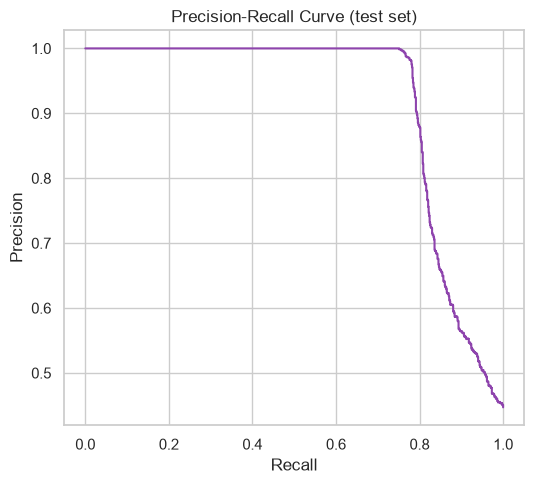

In [22]:
precision_vals, recall_vals, _ = precision_recall_curve(y_test, test_probs)
plt.figure(figsize=(5.5, 5))
plt.plot(recall_vals, precision_vals, color="#8e44ad")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve (test set)")
plt.tight_layout()
plt.savefig(os.path.join(MODEL_DIR, "pr_curve.png"), dpi=120)
plt.show()


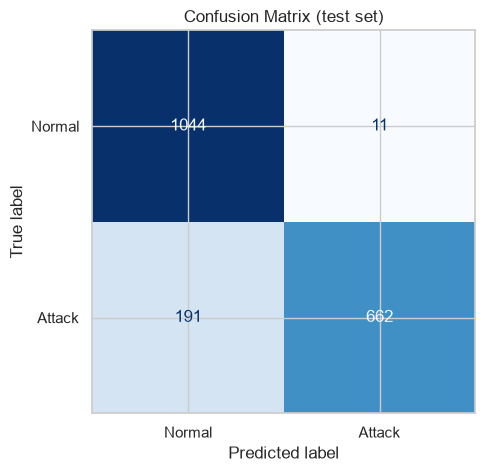

In [23]:
cm = confusion_matrix(y_test, test_preds)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Normal", "Attack"])
fig, ax = plt.subplots(figsize=(5, 5))
disp.plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title("Confusion Matrix (test set)")
plt.tight_layout()
plt.savefig(os.path.join(MODEL_DIR, "confusion_matrix.png"), dpi=120)
plt.show()


## 8. Bonus – Explainable AI (XAI) with SHAP (rubric 2.7)

SHAP (SHapley Additive exPlanations) quantifies how much each input
feature pushed a prediction towards "Attack" or "Normal". This gives the
model interpretability, which matters a lot in a security context: an
analyst needs to know **why** a session was flagged before acting on it.


In [ ]:
%pip install -q shap

import shap

print("SHAP version:", shap.__version__)

# A small, representative background sample speeds up the explainer
# without materially changing the attributions.
background = X_train_proc[np.random.choice(X_train_proc.shape[0], 100, replace=False)]
sample = X_test_proc[:200]

explainer = shap.Explainer(model, background, feature_names=list(feature_names))
shap_values = explainer(sample)

shap.summary_plot(shap_values, sample, feature_names=list(feature_names), show=False)
plt.tight_layout()
plt.savefig(os.path.join(MODEL_DIR, "shap_summary.png"), dpi=120, bbox_inches="tight")
plt.show()


ModuleNotFoundError: No module named 'shap'

In [ ]:
# A single-session explanation: why did the model classify this particular
# test-set session the way it did?
idx = 0
print(f"Session #{idx} -> predicted attack probability: {test_probs[idx]:.3f}, "
      f"actual label: {int(y_test.values[idx])}")

single_explanation = shap.Explanation(
    values=shap_values.values[idx],
    base_values=float(np.ravel(shap_values.base_values[idx])[0]),
    data=shap_values.data[idx],
    feature_names=shap_values.feature_names,
)
shap.plots.waterfall(single_explanation, show=False)
plt.tight_layout()
plt.savefig(os.path.join(MODEL_DIR, "shap_waterfall_example.png"), dpi=120, bbox_inches="tight")
plt.show()


## 9. Save the final model

The trained Keras model, fitted preprocessor and evaluation metrics are
saved to `../models/`. The FastAPI service in `../api/api.py` loads these
exact files at startup, so re-running this notebook end-to-end will
automatically refresh what the desktop app serves.


In [ ]:
model.save(os.path.join(MODEL_DIR, "ids_mlp_model.keras"))
print("Saved model, preprocessor and metrics to:", os.path.abspath(MODEL_DIR))
print(os.listdir(MODEL_DIR))


## 10. Next steps

- Start the API: `cd ../api && uvicorn api:app --reload --port 8000`
- Start the desktop app: `cd ../desktop_app && python desktop_app.py`
- See `../theory_report/` for the write-up covering the 30-mark theory
  component (model scenario, architecture, result analysis, real-world
  use of ML/DL in cybersecurity).
